# Task 3 · Car Price Prediction with Machine Learning


## 0. Imports & setup

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


## 1. Load the dataset


In [5]:
df=pd.read_csv("CAR_DETAILS_FROM_CAR_DEKHO.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
print('Shape:', df.shape)
print(df.dtypes, '\n')
print('Nulls per column:\n', df.isnull().sum())
expected = {'name','year','selling_price','km_driven','fuel','seller_type','transmission','owner'}
assert expected.issubset(df.columns), f'Missing columns: {expected - set(df.columns)}'
print('\nColumns OK')

Shape: (4340, 8)
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object 

Nulls per column:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Columns OK


## 2. Data cleaning
- Standardize text (strip whitespace, consistent casing) so `"Petrol"` and `"petrol"` become one category
- Drop duplicates
- Handle nulls (drop rows with missing target; fill numeric with median, categorical with mode)
- Remove impossible values (price/km <= 0)

In [7]:
df_raw_rows = len(df)

# 2a. Inconsistent categorical values
cat_cols = ['name', 'fuel', 'seller_type', 'transmission', 'owner']
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.lower().replace({'nan': np.nan})

# 2b. Duplicates
n_dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicates removed: {n_dups}')

# 2c. Nulls
df = df.dropna(subset=['selling_price', 'year'])           # can't train without target / year
df['km_driven'] = df['km_driven'].fillna(df['km_driven'].median())
for col in ['fuel', 'seller_type', 'transmission', 'owner', 'name']:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2d. Invalid values
df = df[(df['selling_price'] > 0) & (df['km_driven'] >= 0)].reset_index(drop=True)

print(f'Rows: {df_raw_rows} -> {len(df)}')

Duplicates removed: 763
Rows: 4340 -> 3577


In [8]:
assert df.isnull().sum().sum() == 0, 'Still has nulls'
assert df.duplicated().sum() == 0, 'Still has duplicates'
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    print(col, '->', sorted(df[col].unique()))

fuel -> ['cng', 'diesel', 'electric', 'lpg', 'petrol']
seller_type -> ['dealer', 'individual', 'trustmark dealer']
transmission -> ['automatic', 'manual']
owner -> ['first owner', 'fourth & above owner', 'second owner', 'test drive car', 'third owner']


## 3. Feature engineering
- **car_age** = current year − manufacturing year
- **brand** = first word of the car name (e.g. `maruti swift dzire` → `maruti`)

In [9]:
REF_YEAR = int(df['year'].max()) + 1
df['car_age'] = REF_YEAR - df['year']

df['brand'] = df['name'].str.split().str[0]
# Fix known inconsistent brand spellings
df['brand'] = df['brand'].replace({'land': 'land rover', 'mini': 'mini cooper'})

# Group rare brands (<10 cars) into 'other' so one-hot doesn't explode
counts = df['brand'].value_counts()
rare = counts[counts < 10].index
df['brand'] = df['brand'].replace(dict.fromkeys(rare, 'other'))

print('Reference year:', REF_YEAR)
df[['name', 'brand', 'year', 'car_age']].head()

Reference year: 2021


,name,brand,year,car_age
0,maruti 800 ac,maruti,2007,14
1,maruti wagon r lxi minor,maruti,2007,14
2,hyundai verna 1.6 sx,hyundai,2012,9
3,datsun redigo t option,datsun,2017,4
4,honda amaze vx i-dtec,honda,2014,7


In [10]:
assert (df['car_age'] >= 1).all()
print('Brands:', df['brand'].nunique())
print(df['brand'].value_counts().head(10))

Brands: 18
brand
maruti        1072
hyundai        637
mahindra       328
tata           308
ford           220
honda          216
toyota         170
chevrolet      151
renault        110
volkswagen      93
Name: count, dtype: int64


## 4. Exploratory Data Analysis

### 4.1 Distribution of selling prices

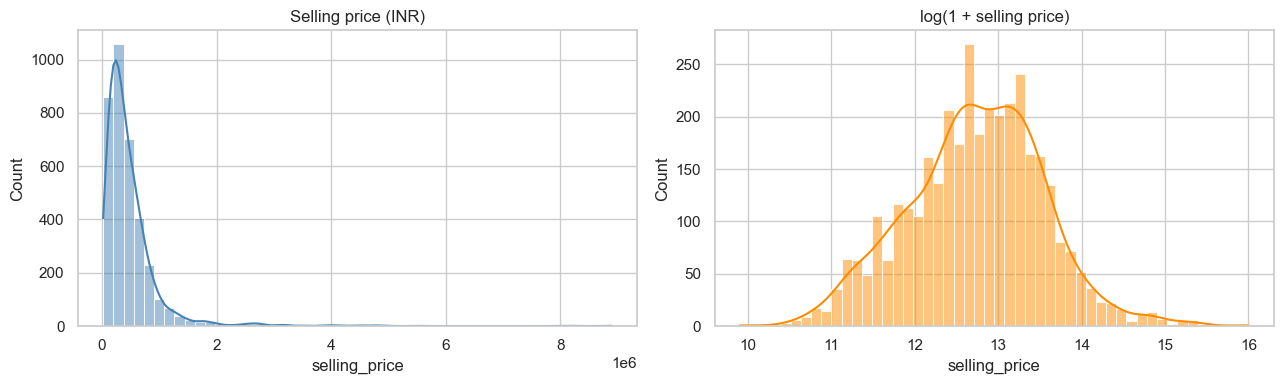

count       3577.0
mean      473913.0
std       509302.0
min        20000.0
25%       200000.0
50%       350000.0
75%       600000.0
max      8900000.0
Name: selling_price, dtype: float64


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['selling_price'], bins=50, kde=True, ax=ax[0], color='steelblue')
ax[0].set_title('Selling price (INR)')
sns.histplot(np.log1p(df['selling_price']), bins=50, kde=True, ax=ax[1], color='darkorange')
ax[1].set_title('log(1 + selling price)')
plt.tight_layout(); plt.show()
print(df['selling_price'].describe().round(0))

Prices are heavily **right-skewed** (a few luxury cars cost far more). 

### 4.2 Price vs. fuel type

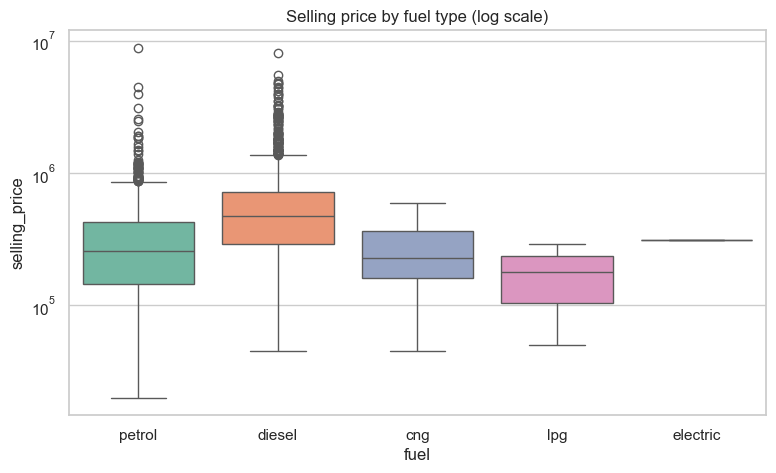

In [12]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='fuel', y='selling_price', palette='Set2')
plt.yscale('log')
plt.title('Selling price by fuel type (log scale)')
plt.show()

### 4.3 Price vs. car age

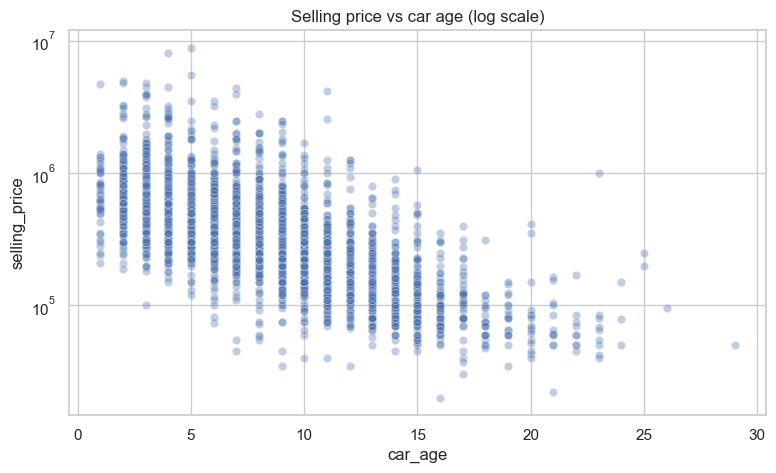

In [13]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='car_age', y='selling_price', alpha=0.35)
plt.yscale('log')
plt.title('Selling price vs car age (log scale)')
plt.show()

Clear trend: **older cars sell for less**. Diesel cars tend to have higher prices than petrol/CNG/LPG in this data.

## 5. Encode categorical variables
- **One-Hot Encoding** for `fuel`, `seller_type`, `transmission`, `owner`, `brand` (no natural order, so label encoding would mislead linear models).
- `name` is dropped (too many unique values; its useful part is already in `brand`). `year` is dropped since `car_age` replaces it.

In [14]:
model_df = df.drop(columns=['name', 'year'])
model_df = pd.get_dummies(model_df,
                          columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'],
                          drop_first=True, dtype=int)
print('Encoded shape:', model_df.shape)
model_df.head()

Encoded shape: (3577, 31)


,selling_price,km_driven,car_age,fuel_diesel,fuel_electric,fuel_lpg,fuel_petrol,seller_type_individual,seller_type_trustmark dealer,transmission_manual,...,brand_mahindra,brand_maruti,brand_mercedes-benz,brand_nissan,brand_other,brand_renault,brand_skoda,brand_tata,brand_toyota,brand_volkswagen
0,60000,70000,14,0,0,0,1,1,0,1,...,0,1,0,0,0,0,0,0,0,0
1,135000,50000,14,0,0,0,1,1,0,1,...,0,1,0,0,0,0,0,0,0,0
2,600000,100000,9,1,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,250000,46000,4,0,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,450000,141000,7,1,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [15]:
assert all(np.issubdtype(t, np.number) for t in model_df.dtypes)
assert model_df.isnull().sum().sum() == 0
print('All columns numeric, no nulls')

All columns numeric, no nulls


## 6. Feature correlation heatmap

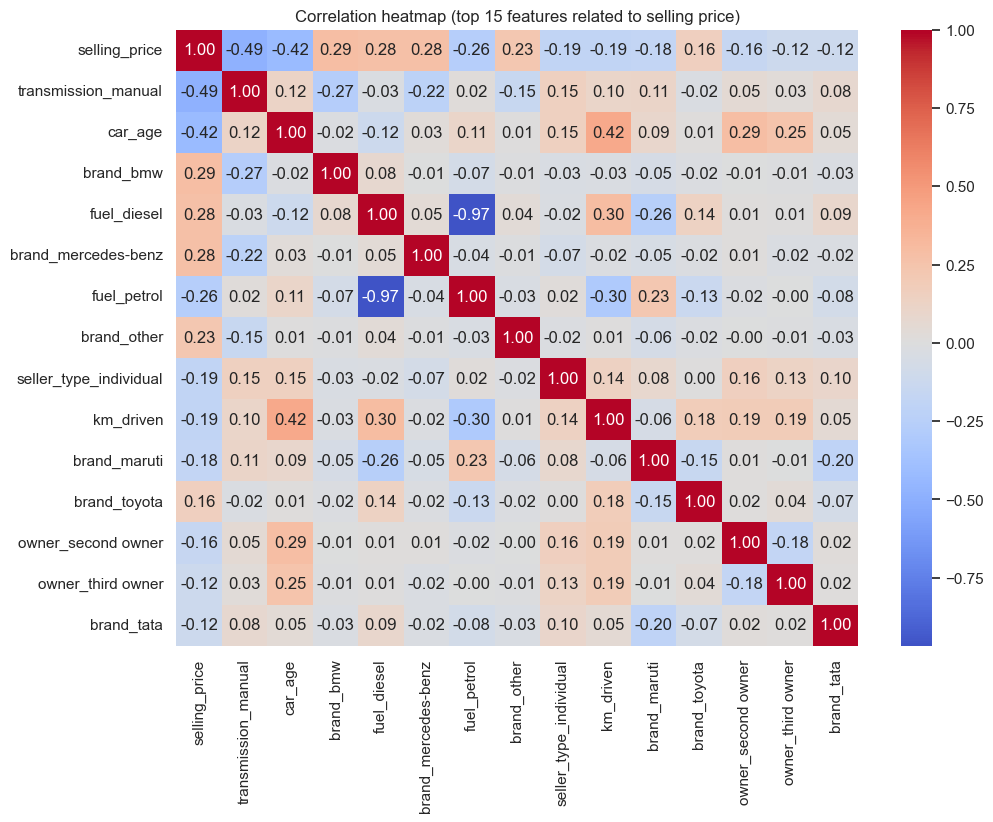

In [16]:
corr = model_df.corr()
top = corr['selling_price'].abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(11, 8))
sns.heatmap(model_df[top].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (top 15 features related to selling price)')
plt.show()

`transmission_manual` and `car_age` typically correlate negatively with price, while diesel and automatic transmission correlate positively.

## 7. Train/test split
80/20 split. Target is `log(1 + price)` to handle skew; we convert predictions back to INR when evaluating so the metrics are in real rupees.

In [17]:
X = model_df.drop(columns=['selling_price'])
y = np.log1p(model_df['selling_price'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (2861, 30) | Test: (716, 30)


In [18]:
assert len(X_train) + len(X_test) == len(X)
assert not set(X_train.index) & set(X_test.index)
print('Split OK, no overlap')

Split OK, no overlap


## 8. Train models
Three models, from simple baseline to stronger ensembles:
1. Linear Regression (baseline)
2. Random Forest Regressor
3. Gradient Boosting Regressor

In [19]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.1,
                                                   max_depth=3, random_state=RANDOM_STATE),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f'Trained: {name}')

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


## 9. Evaluate: MAE, RMSE, R²
Metrics are computed on the **original INR scale** (predictions converted back with `expm1`).

In [20]:
y_test_inr = np.expm1(y_test)
rows = []
preds = {}

for name, m in models.items():
    p = np.expm1(m.predict(X_test))
    preds[name] = p
    rows.append({
        'Model': name,
        'MAE (INR)':  mean_absolute_error(y_test_inr, p),
        'RMSE (INR)': np.sqrt(mean_squared_error(y_test_inr, p)),
        'R²':         r2_score(y_test_inr, p),
        'R² (log scale)': r2_score(y_test, np.log1p(p)),
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
display(results.sort_values('R²', ascending=False))
best_name = results['R²'].idxmax()
print('Best model:', best_name)

,MAE (INR),RMSE (INR),R²,R² (log scale)
Model,,,,
Linear Regression,146658.432,311746.360,0.698,0.777
Gradient Boosting,147086.394,358503.753,0.601,0.785
Random Forest,152437.613,362237.087,0.593,0.753


Best model: Linear Regression


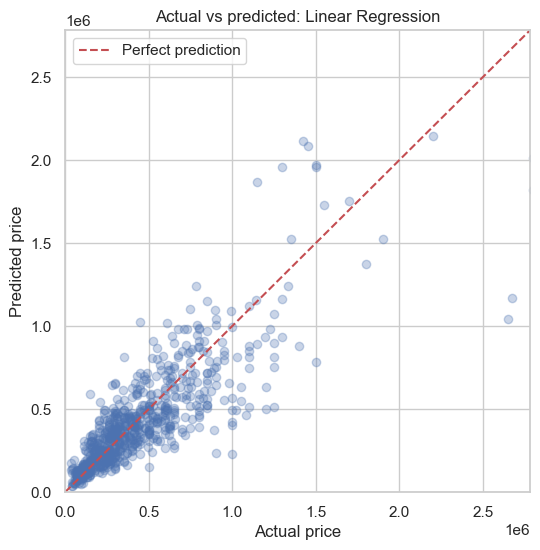

In [21]:
# Actual vs predicted for the best model
plt.figure(figsize=(6, 6))
plt.scatter(y_test_inr, preds[best_name], alpha=0.3)
lim = [0, y_test_inr.quantile(0.99)]
plt.plot(lim, lim, 'r--', label='Perfect prediction')
plt.xlim(lim); plt.ylim(lim)
plt.xlabel('Actual price'); plt.ylabel('Predicted price')
plt.title(f'Actual vs predicted: {best_name}')
plt.legend(); plt.show()

## 10. Feature importance (best model)

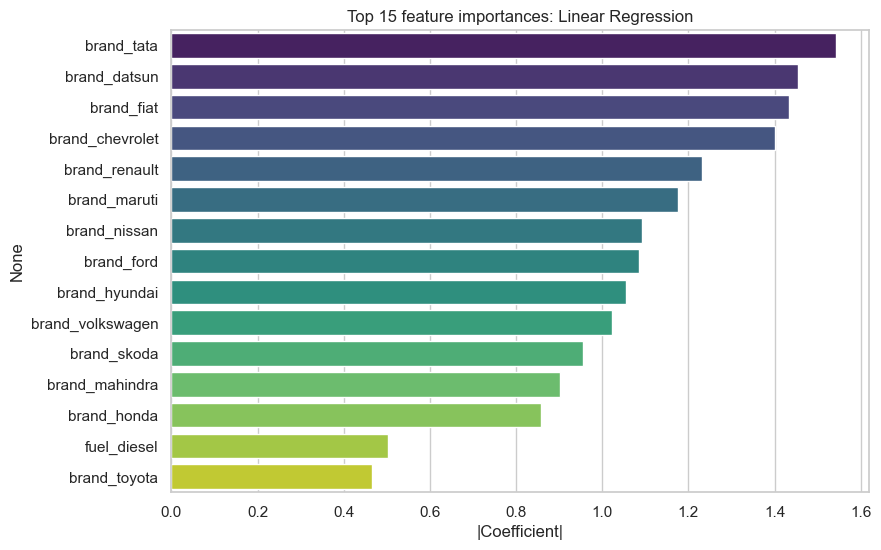

In [22]:
best_model = models[best_name]

if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X.columns)
    xlabel = 'Importance'
else:  # linear model fallback: use absolute coefficients
    imp = pd.Series(np.abs(best_model.coef_), index=X.columns)
    xlabel = '|Coefficient|'

imp = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, palette='viridis')
plt.title(f'Top 15 feature importances: {best_name}')
plt.xlabel(xlabel); plt.show()

## 11. Conclusions
- **Best model:** whichever scored highest R² above (usually Gradient Boosting or Random Forest on this dataset); Linear Regression is the baseline.
- **Key drivers of price:** car age, brand (luxury brands), kilometres driven, fuel (diesel) and transmission.
- **Why log-transform the target:** prices are skewed, and the log helps models fit mainstream cars instead of being dominated by luxury outliers.
- **Possible improvements:** hyperparameter tuning (`GridSearchCV`/`RandomizedSearchCV`), cross-validation, extracting car *model* (not just brand), and trying XGBoost/LightGBM.